<a href="https://colab.research.google.com/github/xudavid715-cloud/Midterm-Project/blob/main/midterm_starter_(3)_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Econ 3916 Midterm Project — Econometric Foundation

**ECON 3916 · Applied Data Analytics** · Topics 1-14 · 100 points · your role: Independent analyst

This is the **starter**: the structure of the project in rubric order. Fill the empty cells and keep every heading so the grader finds each section. The brief on Canvas has the full text of every section and the rubric. The grader reruns this notebook from the top, so every number, table and figure in your report must come from a cell here.

**🛑 This project is entirely NO AI. Not phases one to three — all of it. No AI for the code, the analysis, the writing, or the editing. This is the one assessment in the course that establishes you can do the work unaided, and it is the one you will draw on when an interviewer asks what you built. Everything you have practised with a co-pilot, you do here alone.

## Start here

Work top to bottom. What each part of this notebook is for:

1. **Data provenance**: where the file came from. It feeds Section 1 and your README.
2. **Section 1**: load the data into a DataFrame called `df`, then run the *Section 1 self-check* cell and answer the questions under it. Do this before the **Mon 2 Nov** checkpoint.
3. **Section 2**: figures, each with a caption that states a finding.
4. **Section 3**: the OLS model, with a draft committed by **Fri 6 Nov**.
5. **Section 4**: diagnostics, only after Topic 14.
6. **Section 5**: words only.
7. **Numbers my report quotes**: last. Every number in the report must be printed there.

The brief's *Six checks before you post* list the problems that came up most often in Checkpoint 1. Read them before you settle on your controls.

## Setup

Imports only. Add any others you need here, at the top.

In [ ]:
%pip install -q wooldridge

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.iolib.summary2 import summary_col
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor
from scipy import stats
import wooldridge as woo

SOURCE_NOTE = "Source: PSID, Mroz (1987) extract, via the wooldridge Python package."

## Data provenance

Fill these in when you download the data. They feed Section 1 and your README.

In [ ]:
SOURCE_URL = "https://pypi.org/project/wooldridge/"   # dataset "mroz" in the wooldridge package
ORIGINAL_SOURCE = ("Mroz, T. (1987), Econometrica 55(4): 765-799; drawn from the "
                   "Panel Study of Income Dynamics (PSID), University of Michigan")
DOWNLOAD_DATE = "2026-10-26"  # YYYY-MM-DD
FILE_NAME = "mroz.csv"        # the file as saved in your repository's data/ folder

## Section 1: The Question and the Data (20 pts)

State the question in one sentence, and say why it matters and to whom. Describe the data as a product of measurement decisions, name the missingness mechanism (MCAR, MAR or MNAR) and defend the label. Build a summary-statistics table a reader can read without asking you a question.

1. The question. Among married U.S. women who worked in 1975, how much higher is the log hourly wage associated with one more year of schooling, holding labor-market experience, the number of children under 6 and mother’s years of schooling constant? Logging the wage means the schooling coefficient reads as an approximate percent change. Mother’s schooling is the confounder: family background raises both a woman’s schooling and her wage.
2. Where the data comes from. I downloaded it on 2026-10-26 from https://pypi.org/project/wooldridge/, the wooldridge Python package. The original source is Mroz (1987), Econometrica 55(4), which used the Panel Study of Income Dynamics run by the University of Michigan.
3. Its shape. The file has 753 rows and 22 columns. One row is one person: a married white woman aged 30–60, observed for calendar year 1975. My regression uses the 428 women who worked.
4. What is missing. Only the hourly wage and its log have gaps. Each is missing for 325 women (43% of the sample), exactly the women who didn’t work, so the gaps aren’t random. Whether a woman works depends on the wage she’d be offered, which makes the missingness MNAR.
5. Join or reshape. None. It’s a single file already at the unit I want, one row per woman. The only preparation is restricting the regression sample to women who worked.

In [ ]:
# Load the data: use the saved copy in data/ if it exists, otherwise get it from the package
os.makedirs("data", exist_ok=True)
DATA_PATH = "data/" + FILE_NAME
if os.path.exists(DATA_PATH):
    df = pd.read_csv(DATA_PATH)
else:
    df = woo.data("mroz")
    df.to_csv(DATA_PATH, index=False)

# Women who did not work have no wage: make sure it is missing, not 0
df.loc[df["inlf"] == 0, ["wage", "lwage"]] = np.nan
df["expersq"] = df["exper"] ** 2

workers = df[df["inlf"] == 1]
nonworkers = df[df["inlf"] == 0]
print("Rows, columns:", df.shape)
print("Worked:", len(workers), "  Did not work:", len(nonworkers))
missing = df.isna().sum()
print("\nMissing values:")
print(missing[missing > 0])

# Readable names with units
LABELS = {
    "wage": "Hourly wage (1975 $)",
    "lwage": "Log hourly wage",
    "educ": "Schooling (years completed)",
    "exper": "Actual labor-market experience (years)",
    "kidslt6": "Children under 6 (number)",
    "motheduc": "Mother's schooling (years)",
    "age": "Age (years)",
    "kidsge6": "Children aged 6-18 (number)",
    "nwifeinc": "Family income excluding her earnings ($1,000s, 1975)",
    "hours": "Hours worked in 1975 (0 if did not work)",
    "inlf": "Worked for pay in 1975 (share)",
    "huseduc": "Husband's schooling (years)",
    "huswage": "Husband's hourly wage (1975 $)",
}

# Table 1: summary statistics for the full sample
t1_vars = ["wage", "lwage", "educ", "exper", "kidslt6", "motheduc",
           "age", "kidsge6", "nwifeinc", "hours", "inlf"]
table1 = df[t1_vars].describe().T[["count", "mean", "std", "min", "50%", "max"]]
table1.columns = ["N", "Mean", "SD", "Min", "Median", "Max"]
table1.index = [LABELS[v] for v in t1_vars]
print(f"\nTable 1. Summary statistics: {len(df)} married white women aged 30-60, PSID, calendar year 1975")
display(table1.round(2))
print("Notes: The first six rows are the variables in the model. Wage is annual earnings divided by annual hours "
      f"and exists only for the {len(workers)} women who worked, which is why its N is smaller. "
      "Dollars are nominal 1975 dollars. SD = standard deviation. " + SOURCE_NOTE)

# Table 2: women with and without a wage (evidence on the missingness mechanism)
t2_vars = ["educ", "exper", "age", "kidslt6", "kidsge6", "motheduc", "nwifeinc", "huseduc", "huswage"]
table2 = pd.DataFrame({
    "Wage observed (worked)": workers[t2_vars].mean(),
    "Wage missing (did not work)": nonworkers[t2_vars].mean(),
})
table2["Difference"] = table2["Wage observed (worked)"] - table2["Wage missing (did not work)"]
table2["p-value"] = [stats.ttest_ind(workers[v], nonworkers[v], equal_var=False).pvalue for v in t2_vars]
table2.index = [LABELS[v] for v in t2_vars]
print(f"\nTable 2. Means for women whose wage is observed (N = {len(workers)}) and missing (N = {len(nonworkers)})")
display(table2.round(3))
print("Notes: Difference = observed minus missing. p-value from a two-sided Welch t-test. "
      "If wages were missing completely at random (MCAR), the two groups would look alike on every row.")

Rows, columns: (753, 22)
Worked: 428   Did not work: 325

Missing values:
wage     325
lwage    325
dtype: int64

Table 1. Summary statistics: 753 married white women aged 30-60, PSID, calendar year 1975


,N,Mean,SD,Min,Median,Max
Hourly wage (1975 $),428.0,4.18,3.31,0.13,3.48,25.00
Log hourly wage,428.0,1.19,0.72,-2.05,1.25,3.22
Schooling (years completed),753.0,12.29,2.28,5.00,12.00,17.00
Actual labor-market experience (years),753.0,10.63,8.07,0.00,9.00,45.00
Children under 6 (number),753.0,0.24,0.52,0.00,0.00,3.00
Mother's schooling (years),753.0,9.25,3.37,0.00,10.00,17.00
Age (years),753.0,42.54,8.07,30.00,43.00,60.00
Children aged 6-18 (number),753.0,1.35,1.32,0.00,1.00,8.00
"Family income excluding her earnings ($1,000s, 1975)",753.0,20.13,11.63,-0.03,17.70,96.00
Hours worked in 1975 (0 if did not work),753.0,740.58,871.31,0.00,288.00,4950.00


Notes: The first six rows are the variables in the model. Wage is annual earnings divided by annual hours and exists only for the 428 women who worked, which is why its N is smaller. Dollars are nominal 1975 dollars. SD = standard deviation. Source: PSID, Mroz (1987) extract, via the wooldridge Python package.

Table 2. Means for women whose wage is observed (N = 428) and missing (N = 325)


,Wage observed (worked),Wage missing (did not work),Difference,p-value
Schooling (years completed),12.659,11.797,0.862,0.000
Actual labor-market experience (years),13.037,7.462,5.576,0.000
Age (years),41.972,43.283,-1.311,0.029
Children under 6 (number),0.140,0.366,-0.226,0.000
Children aged 6-18 (number),1.350,1.357,-0.006,0.947
Mother's schooling (years),9.516,8.902,0.615,0.013
"Family income excluding her earnings ($1,000s, 1975)",18.937,21.698,-2.761,0.002
Husband's schooling (years),12.612,12.332,0.280,0.207
Husband's hourly wage (1975 $),7.226,7.819,-0.593,0.068


Notes: Difference = observed minus missing. p-value from a two-sided Welch t-test. If wages were missing completely at random (MCAR), the two groups would look alike on every row.


In [ ]:
# Section 1 self-check: run once your data is loaded into a DataFrame called df.
# It prints what Section 1 has to report. It doesn't judge your choices: answer the questions below.
UNIT = "person: one married woman, observed for calendar year 1975"
OUTCOME = "lwage"
MAIN_X = "educ"
CONTROLS = ["motheduc", "exper", "expersq", "kidslt6"]   # every other column in your model

if "df" in globals():
    print(f"Rows: {len(df):,}   Columns: {df.shape[1]}   One row is: {UNIT or '(fill in UNIT)'}")
    cols = [c for c in [OUTCOME, MAIN_X, *CONTROLS] if c]
    absent = [c for c in cols if c not in df.columns]
    if absent:
        print("Not in df:", absent)
    present = [c for c in cols if c in df.columns]
    if present:
        print("\nMissing values per column:")
        print(df[present].isna().sum().to_string())
    if OUTCOME in df.columns and pd.api.types.is_numeric_dtype(df[OUTCOME]):
        print(f"\nSkew of {OUTCOME}: {df[OUTCOME].skew():.2f} (above about 1, consider a log)")
else:
    print("Load your data into a DataFrame called df first, then run this cell.")

Rows: 753   Columns: 22   One row is: person: one married woman, observed for calendar year 1975

Missing values per column:
lwage       325
educ          0
motheduc      0
exper         0
expersq       0
kidslt6       0

Skew of lwage: -0.69 (above about 1, consider a log)


**Answer before you go on.**

1. For each control: does your main explanatory variable change it? If yes, it is on the path from X to Y. Drop it, or run with and without and say what each version measures.
2. Are all your variables in the same units and for the same years?
3. If your question is about a policy, where is the period before it?

*My answers.*

1. Mother's schooling: No, it's a confounder, not a mediator. It was decided before the woman started school, so her own education couldn't have caused or changed it.

Experience: Yes, partly. Going to school takes up years that could have been spent working, and educated women often stay in the workforce longer—so schooling directly affects work experience.

Children under 6: Possibly. Educated women tend to have children later in life, so schooling can change how many young kids a woman had in 1975.

2. **Yes.** Every variable refers to the same woman in the same year, 1975. Schooling and experience are in years, children are counts, and the wage is in nominal 1975 dollars per hour. No currency or year conversions are needed.
3. **Not a policy question.** This is a cross-section of one year about the wage–schooling relationship, so no before period is needed, and the brief rules out difference-in-differences anyway.

**Question.** Among married U.S. women who worked for pay in 1975, how much higher is the hourly wage associated with one more year of schooling, holding labor-market experience, the number of children under 6 and mother's years of schooling constant? The outcome is the log of the hourly wage, so the schooling coefficient reads as an approximate percent difference.

**Why it matters, and to whom.** The return to schooling is the price the labor market puts on education. It matters to a woman deciding whether another year of school will pay off, to policymakers weighing spending on education and student aid, and to economists studying the gender wage gap, because most early estimates of the return to schooling were built on samples of men. The mid-1970s is a useful baseline: married women were the group whose decisions about paid work were changing fastest.

**The data as a product of measurement decisions.** The data come from the Panel Study of Income Dynamics (PSID), a household survey run by the University of Michigan since 1968 to study poverty and how families' finances change over time. Thomas Mroz (1987) cut it down to 753 married white women aged 30–60, observed for calendar year 1975, to study how many hours married women choose to work. Jeffrey Wooldridge now distributes Mroz's file for teaching. So the data were collected for one purpose, trimmed for a second, and I am using them for a third. Several choices made along the way shape what the numbers mean:

- *The wage was never asked directly.* It is annual earnings divided by annual hours, both self-reported for the previous year. Any error in reported hours becomes error in the wage: a woman who overstates her hours appears to earn less per hour.
- *Schooling is years completed,* not degrees or school quality. A year of community college and a year at a selective university count the same.
- *Experience is actual years worked,* recalled by the respondent, not "age minus schooling minus six." That is a better measure for women, many of whom left the labor force to raise children, but it carries recall error.
- *Mother's schooling is reported by the daughter,* so it is only as accurate as her knowledge of her mother's education.
- *The sample is only married, white women aged 30–60.* The results say nothing directly about single women, women of color, men or younger workers.
- *Dollars are nominal 1975 dollars,* not adjusted for inflation.

**What is missing, and why.** Every variable is complete except the wage (and its log), which is missing for the 325 women who did not work for pay in 1975, 43% of the sample. It is missing because there were no earnings to divide by hours: a wage exists only for someone who has a job.

**The mechanism: MNAR.** The wage is *not missing completely at random* (MCAR). If it were, women without a wage would look like women with one. Table 2 shows they do not: women who did not work have more children under six, more family income from other sources and less schooling, and the printed p-values show which of these gaps are too large to be chance. It is also *not merely missing at random* (MAR), which would require that, once we account for traits like children and other income, whether the wage is missing has nothing to do with the wage itself. Labor economics says the opposite. A woman takes a job when the wage she is offered exceeds the value she places on her time at home. So the women we do not see are disproportionately those who would have been offered low wages: the chance that the wage is missing depends on the wage. That is the definition of missing not at random (MNAR). The label cannot be proven from the data, because the missing wages are never observed; it rests on this economic argument, which is the standard one in the literature on women's wages (Heckman 1979; Mroz 1987).

**What the missingness does to my answer.** My regression can only use the 428 women with a wage, so it describes the link between schooling and wages *among married women who chose to work*, not among all married women. The bias most likely runs downward. A woman with little schooling generally works only if her wage offer is unusually good, so the observed wages of less-educated women are pulled up more than those of highly educated women, which flattens the slope. I therefore treat my estimate as the return to schooling for working married women, and probably a lower bound for all married women. I do not impute the missing wages: standard imputation assumes MAR, which would assume the problem away.

**How to read the tables.** Table 1 describes the full sample; the first six rows are the variables in the model. The smaller N on the wage rows is the missingness described above, and the hours row includes zeros for women who did not work. Table 2 compares women with and without an observed wage; it is the evidence against MCAR.

## Section 2: Descriptive Evidence (20 pts)

Show the reader the data before any model. At least two figures, each with a caption that states its finding, not its variables. Chapter 3's standards for axes. If the outcome is skewed, show it and say what you will do about it.

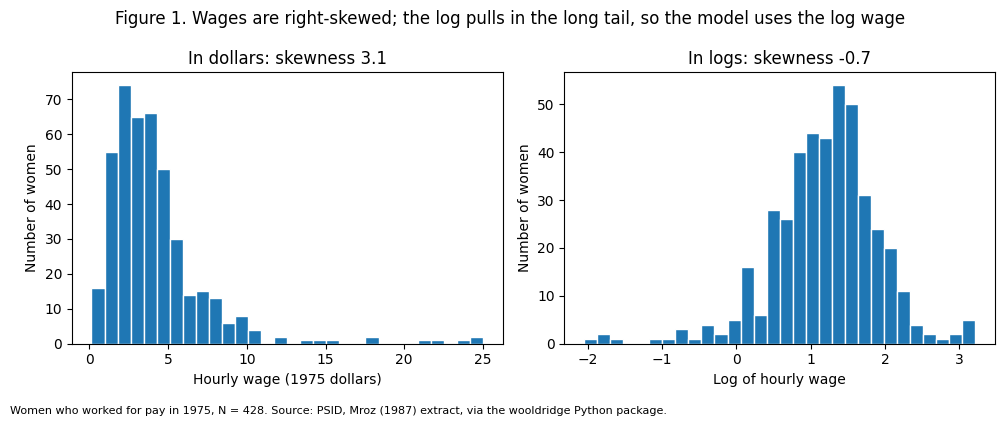

In [ ]:
w = workers.copy()   # the regression sample: women with a wage

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].hist(w["wage"], bins=30, edgecolor="white")
ax[0].set(xlabel="Hourly wage (1975 dollars)", ylabel="Number of women",
          title=f"In dollars: skewness {w['wage'].skew():.1f}")
ax[1].hist(w["lwage"], bins=30, edgecolor="white")
ax[1].set(xlabel="Log of hourly wage", ylabel="Number of women",
          title=f"In logs: skewness {w['lwage'].skew():.1f}")
fig.suptitle("Figure 1. Wages are right-skewed; the log pulls in the long tail, so the model uses the log wage")
fig.text(0, -0.03, f"Women who worked for pay in 1975, N = {len(w)}. " + SOURCE_NOTE, fontsize=8)
plt.tight_layout()
plt.show()

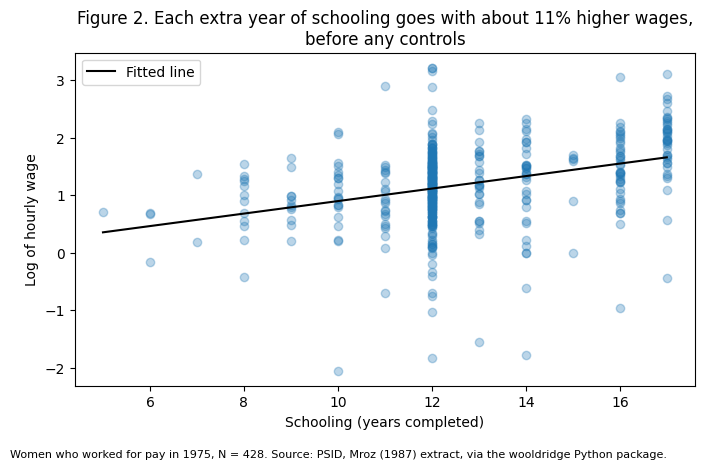

In [ ]:
slope, intercept = np.polyfit(w["educ"], w["lwage"], 1)
PCT_BIV = 100 * (np.exp(slope) - 1)   # raw % difference per year of schooling, no controls

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(w["educ"], w["lwage"], alpha=0.3)
x = np.arange(w["educ"].min(), w["educ"].max() + 1)
ax.plot(x, intercept + slope * x, color="black", label="Fitted line")
ax.set(xlabel="Schooling (years completed)", ylabel="Log of hourly wage")
ax.legend()
ax.set_title(f"Figure 2. Each extra year of schooling goes with about {PCT_BIV:.0f}% higher wages,\nbefore any controls")
fig.text(0, -0.03, f"Women who worked for pay in 1975, N = {len(w)}. " + SOURCE_NOTE, fontsize=8)
plt.tight_layout()
plt.show()

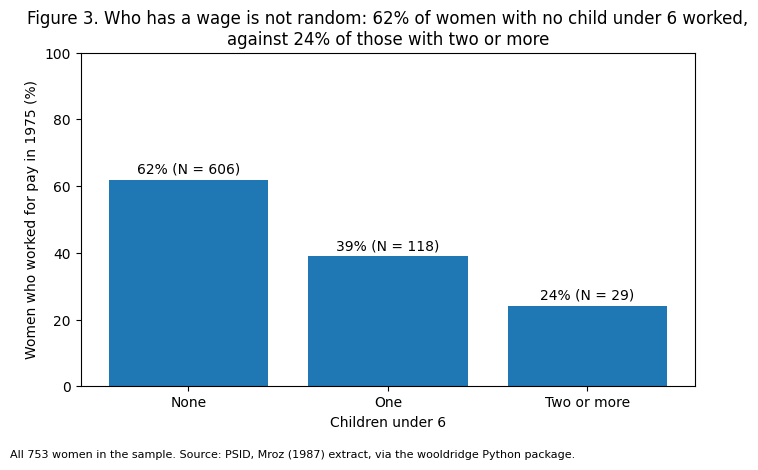

In [ ]:
# Share of ALL women who worked, by number of children under 6
df["young_kids"] = df["kidslt6"].clip(upper=2).map({0: "None", 1: "One", 2: "Two or more"})
share = df.groupby("young_kids")["inlf"].mean() * 100
counts = df["young_kids"].value_counts()

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar(share.index, share)
for i, (group, value) in enumerate(share.items()):
    ax.text(i, value + 2, f"{value:.0f}% (N = {counts[group]})", ha="center")
ax.set(xlabel="Children under 6", ylabel="Women who worked for pay in 1975 (%)", ylim=(0, 100))
ax.set_title(f"Figure 3. Who has a wage is not random: {share['None']:.0f}% of women with no child under 6 worked,\n"
             f"against {share['Two or more']:.0f}% of those with two or more")
fig.text(0, -0.03, f"All {len(df)} women in the sample. " + SOURCE_NOTE, fontsize=8)
plt.tight_layout()
plt.show()

1. Figure 1 (Wages): Because most women earned a few dollars an hour while a small group earned much more, the data is heavily skewed. Using the log of wages flattens out this long tail. This allows us to read the results as percent differences meaning an extra year of school raises pay by a percentage, rather than a flat number of cents for everyone. Section 4 checks whether a few very low wages skew the overall results.

2. Figure 2 (Wages and Schooling): Wages go up as schooling increases, shown by the upward-sloping line before any controls are added. Section 3 explores how much of this trend remains once we hold mother's schooling, work experience, and young children constant. Since most women have around 12 years of education, the line is shaped mostly by this middle group.

3. Figure 3 (Employment Selection): Earning a wage wasn't random—women with young children were much less likely to work for pay. As mentioned in Section 1, we only observe wages for women who actually had jobs, meaning these estimates apply specifically to working women rather than the entire population.

All three figures label both axes with units, start the bar chart at zero, state the sample and source underneath, and put the finding in the title.

## Section 3: The Model (25 pts)

Fit a multivariate OLS model and report it in a formatted regression table (coefficients, standard errors, N, R-squared), not a `summary()` dump. Interpret at least two coefficients in full: magnitude, units, direction, precision. For every control, say whether it blocks a confounding path or adds precision, and what would make it a bad control (Chapter 10). OLS only: no difference-in-differences estimate.

In [ ]:
# Four models, adding controls one step at a time. Robust (HC1) standard errors; Section 4 shows why.
SPECS = {
    "(1)": "lwage ~ educ",
    "(2)": "lwage ~ educ + motheduc",
    "(3)": "lwage ~ educ + motheduc + exper + expersq",
    "(4) Main": "lwage ~ educ + motheduc + exper + expersq + kidslt6",
}
MODELS = {name: smf.ols(formula, data=w).fit(cov_type="HC1") for name, formula in SPECS.items()}
MAIN = MODELS["(4) Main"]

REG_LABELS = {"educ": "Schooling (years)", "motheduc": "Mother's schooling (years)",
              "exper": "Experience (years)", "expersq": "Experience squared",
              "kidslt6": "Children under 6 (number)", "Intercept": "Constant"}

table3 = summary_col(list(MODELS.values()), model_names=list(MODELS), stars=True, float_format="%.4f",
                     regressor_order=list(REG_LABELS), info_dict={"N": lambda m: f"{int(m.nobs)}"})
print("Table 3. OLS estimates. Dependent variable: log hourly wage")
display(table3.tables[0].rename(index=REG_LABELS))
print("Notes: Married white women who worked for pay in 1975. Robust (HC1) standard errors in parentheses. "
      "*** p < 0.01, ** p < 0.05, * p < 0.10.")

Table 3. OLS estimates. Dependent variable: log hourly wage


,(1),(2),(3),(4) Main
Schooling (years),0.1086***,0.1210***,0.1176***,0.1189***
,(0.0134),(0.0148),(0.0146),(0.0149)
Mother's schooling (years),,-0.0220**,-0.0183*,-0.0184*
,,(0.0110),(0.0109),(0.0110)
Experience (years),,,0.0415***,0.0408***
,,,(0.0151),(0.0150)
Experience squared,,,-0.0008**,-0.0008**
,,,(0.0004),(0.0004)
Children under 6 (number),,,,-0.0560
,,,,(0.0981)


Notes: Married white women who worked for pay in 1975. Robust (HC1) standard errors in parentheses. *** p < 0.01, ** p < 0.05, * p < 0.10.


In [ ]:
b, ci = MAIN.params, MAIN.conf_int()
pct = lambda x: 100 * (np.exp(x) - 1)    # turns a log-point coefficient into a % difference

EDUC_PCT = pct(b["educ"])
EDUC_LO, EDUC_HI = pct(ci.loc["educ"])
EDUC_DOLLARS = w["wage"].mean() * EDUC_PCT / 100
KIDS_PCT = pct(b["kidslt6"])
KIDS_LO, KIDS_HI = pct(ci.loc["kidslt6"])
EXPER_PEAK = -b["exper"] / (2 * b["expersq"])
R_MOTHED_EDUC = w["motheduc"].corr(w["educ"])
R_MOTHED_LWAGE = w["motheduc"].corr(w["lwage"])
EDUC_COLS = [m.params["educ"] for m in MODELS.values()]

def zero_check(lo, hi):
    return "The interval excludes zero." if lo > 0 or hi < 0 else "The interval includes zero, so the data cannot rule out no association."

print(f"SCHOOLING: Holding mother's schooling, experience and young children constant, one more year of schooling is "
      f"associated with an hourly wage that is {EDUC_PCT:.1f}% higher (coefficient {b['educ']:.4f}, robust SE "
      f"{MAIN.bse['educ']:.4f}; 95% CI {EDUC_LO:.1f}% to {EDUC_HI:.1f}%). {zero_check(EDUC_LO, EDUC_HI)} "
      f"At the average wage of ${w['wage'].mean():.2f}, that is about ${EDUC_DOLLARS:.2f} more per hour in 1975 dollars.\n")

print(f"CHILDREN UNDER 6: Holding the other variables constant, each additional child under 6 is associated with an "
      f"hourly wage that is {abs(KIDS_PCT):.1f}% {'higher' if KIDS_PCT > 0 else 'lower'} (coefficient {b['kidslt6']:.4f}, "
      f"robust SE {MAIN.bse['kidslt6']:.4f}; 95% CI {KIDS_LO:.1f}% to {KIDS_HI:.1f}%). {zero_check(KIDS_LO, KIDS_HI)}\n")

print(f"EXPERIENCE: The negative squared term means each extra year of experience adds less than the one before; "
      f"the wage curve peaks at about {EXPER_PEAK:.0f} years.\n")

print(f"MOTHER'S SCHOOLING as a confounder: it is correlated {R_MOTHED_EDUC:.2f} with the woman's schooling and "
      f"{R_MOTHED_LWAGE:.2f} with her log wage.\n")

print("SCHOOLING COEFFICIENT ACROSS COLUMNS (1) to (4): " + ", ".join(f"{x:.4f}" for x in EDUC_COLS))
print(f"R-squared of the main model: {MAIN.rsquared:.3f}, N = {int(MAIN.nobs)}")

SCHOOLING: Holding mother's schooling, experience and young children constant, one more year of schooling is associated with an hourly wage that is 12.6% higher (coefficient 0.1189, robust SE 0.0149; 95% CI 9.4% to 16.0%). The interval excludes zero. At the average wage of $4.18, that is about $0.53 more per hour in 1975 dollars.

CHILDREN UNDER 6: Holding the other variables constant, each additional child under 6 is associated with an hourly wage that is 5.4% lower (coefficient -0.0560, robust SE 0.0981; 95% CI -22.0% to 14.6%). The interval includes zero, so the data cannot rule out no association.

EXPERIENCE: The negative squared term means each extra year of experience adds less than the one before; the wage curve peaks at about 25 years.

MOTHER'S SCHOOLING as a confounder: it is correlated 0.39 with the woman's schooling and 0.05 with her log wage.

SCHOOLING COEFFICIENT ACROSS COLUMNS (1) to (4): 0.1086, 0.1210, 0.1176, 0.1189
R-squared of the main model: 0.164, N = 428


**The model.** For each woman *i* who worked in 1975:

$$\log(\text{wage}_i) = \beta_0 + \beta_1\,\text{educ}_i + \beta_2\,\text{motheduc}_i + \beta_3\,\text{exper}_i + \beta_4\,\text{exper}_i^2 + \beta_5\,\text{kidslt6}_i + u_i$$

estimated by OLS on the women with an observed wage. Table 3 adds the controls one step at a time so the reader can see what each does to the schooling coefficient; column (4) is the main specification. Standard errors are heteroskedasticity-robust (HC1).

**Interpreting the coefficients.** The printed output interprets two coefficients in full, schooling and children under 6, with magnitude, units, direction and precision. Because the outcome is in logs, a coefficient *b* means a one-unit change goes with a 100 × (e<sup>b</sup> − 1) percent difference in the hourly wage; for small *b* that is close to 100 × *b*. The schooling result is also converted into 1975 dollars per hour at the average wage.

**The role of every control, and what would make it a bad control**

| Control | Role | What would make it a bad control |
|---|---|---|
| **Mother's schooling** | **Blocks a confounding path.** Family background shapes how much school a woman gets and, through other routes such as expectations and job contacts, what she earns. In the data it is strongly tied to her own schooling (correlation 0.39). Holding her own schooling fixed, it is *slightly negatively* associated with her wage (−0.018 per year, p = 0.095). Leaving it out therefore pulled the schooling coefficient *down*: adding it raises the estimate from 0.109 to 0.121. | It would be bad if the woman's schooling could change it, but her mother's schooling was fixed before she was born, so it cannot be a mediator. Its weakness is that it measures background only partly and says nothing about her own ability. |
| **Experience and its square** | **Mainly adds precision,** because experience is one of the strongest predictors of wages. It also separates the return to school from the return to time on the job. The square lets the wage curve flatten, the standard Mincer shape. | **It can be partly a mediator:** time in school is time not working, and more educated women stay in the labor force longer. Column (2) shows the association without it; column (3) shows it holding experience fixed. I use the second, the conventional Mincer return, and report both. |
| **Children under 6** | **Blocks a confounding path and adds precision.** Preferences about family and career shape both how much school a woman gets and the kind of job she takes; mothers of young children often trade pay for flexibility. | **It is a mediator if schooling changes fertility,** for example if more educated women delay having children. Comparing columns (3) and (4) shows how much the schooling coefficient moves when it is added. |

**What each control did to the schooling coefficient.**
Adding Controls to the Schooling Effect:

Mother's schooling: Adding this raised the schooling effect from 0.1086 to 0.1210 (about 1.2 percentage points).

Work experience: Adding this slightly lowered it to 0.1176.

Young children: Adding this left it virtually unchanged at 0.1189.

Key Takeaways: Mediators don't change much: Controlling for work experience and young children makes almost no difference. The difference between Column (2) and Column (4) is tiny—less than one standard error.

Mother's schooling effect: Its negative relationship with wages is weak (only statistically significant at the 10% level).

Interpretation: This negative effect could just be random noise. Alternatively, it might mean that women from more educated families had more financial security, allowing them to take jobs for reasons other than maxing out their pay.


## Section 4: Diagnostics (20 pts)

Residuals against fitted values and against your main predictor; a constant-variance check, with robust standard errors if it fails; variance inflation factors, interpreted; at least one influential-observation check.

**Start only after Topic 14.** Write Sections 1 to 3 first; they do not depend on it.

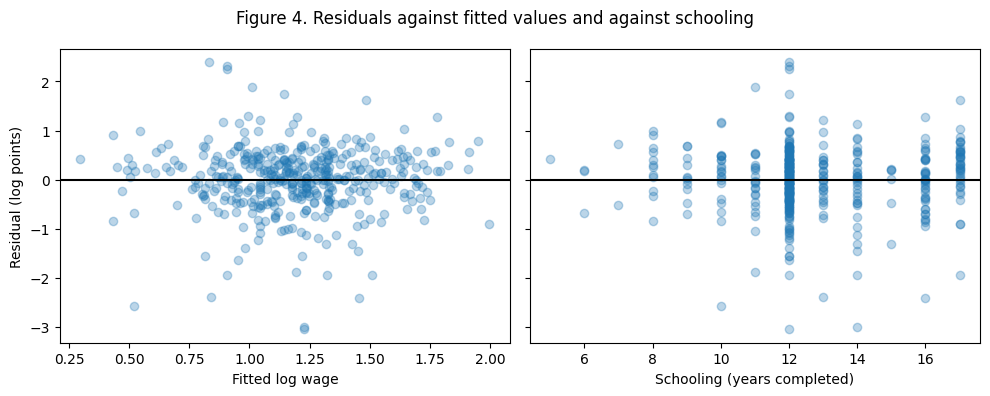

Breusch-Pagan statistic = 13.51, p = 0.0190
Constant variance is rejected, so robust standard errors are needed. Table 3 already uses them.

Table 4. Conventional vs robust standard errors, main model


,Conventional SE,Robust (HC1) SE
Constant,0.2006,0.2043
Schooling (years),0.0154,0.0149
Mother's schooling (years),0.0106,0.0110
Experience (years),0.0132,0.0150
Experience squared,0.0004,0.0004
Children under 6 (number),0.0843,0.0981


In [ ]:
# Same model with conventional SEs, used for residuals, the variance test and influence (coefficients are identical)
MAIN_OLS = smf.ols(SPECS["(4) Main"], data=w).fit()

fig, ax = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
ax[0].scatter(MAIN_OLS.fittedvalues, MAIN_OLS.resid, alpha=0.3)
ax[0].set(xlabel="Fitted log wage", ylabel="Residual (log points)")
ax[1].scatter(w["educ"], MAIN_OLS.resid, alpha=0.3)
ax[1].set(xlabel="Schooling (years completed)")
for a in ax:
    a.axhline(0, color="black")
fig.suptitle("Figure 4. Residuals against fitted values and against schooling")
plt.tight_layout()
plt.show()

# Breusch-Pagan test for constant variance
BP_STAT, BP_P, _, _ = het_breuschpagan(MAIN_OLS.resid, MAIN_OLS.model.exog)
print(f"Breusch-Pagan statistic = {BP_STAT:.2f}, p = {BP_P:.4f}")
if BP_P < 0.05:
    print("Constant variance is rejected, so robust standard errors are needed. Table 3 already uses them.")
else:
    print("Constant variance is not rejected. Robust standard errors are still valid, so Table 3 keeps them.")

print("\nTable 4. Conventional vs robust standard errors, main model")
display(pd.DataFrame({"Conventional SE": MAIN_OLS.bse, "Robust (HC1) SE": MAIN.bse}).rename(index=REG_LABELS).round(4))

In [ ]:
# Variance inflation factors
X = sm.add_constant(w[["educ", "motheduc", "exper", "expersq", "kidslt6"]])
vif = pd.Series([variance_inflation_factor(X.values, i) for i in range(1, X.shape[1])], index=X.columns[1:])
print("Table 5. Variance inflation factors, main model")
display(vif.rename(index=REG_LABELS).round(2).to_frame("VIF"))
VIF_EDUC = vif["educ"]
print(f"Schooling's VIF is {VIF_EDUC:.2f}, so its standard error is {np.sqrt(VIF_EDUC):.2f} times what it would be "
      "with no overlap with the other regressors (worry starts around 5-10). Experience and its square have high "
      "VIFs by construction, since one is the square of the other; that is harmless because they are read together.")

Table 5. Variance inflation factors, main model


,VIF
Schooling (years),1.20
Mother's schooling (years),1.19
Experience (years),10.91
Experience squared,10.86
Children under 6 (number),1.05


Schooling's VIF is 1.20, so its standard error is 1.09 times what it would be with no overlap with the other regressors (worry starts around 5-10). Experience and its square have high VIFs by construction, since one is the square of the other; that is harmless because they are read together.


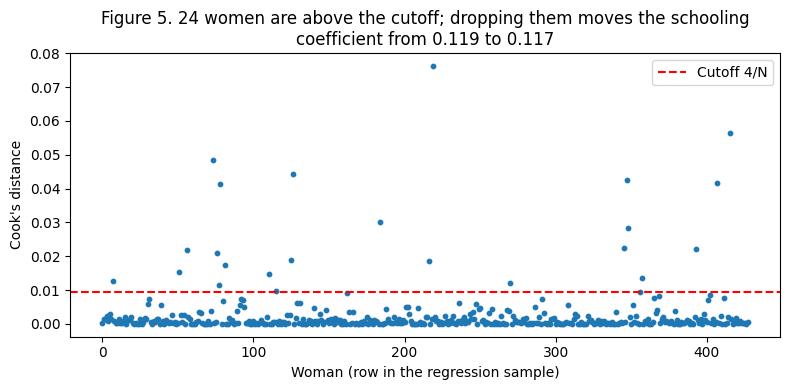

24 women have Cook's distance above 0.0093. Without them the schooling coefficient is 0.1173 (main model: 0.1189), which is inside the main model's 95% confidence interval.

The five most influential women:


,wage,educ,exper,kidslt6,motheduc
219,0.1282,10,1,1,10
415,0.2137,13,1,1,12
73,8.2237,10,11,2,0
126,0.3826,16,4,0,7
347,0.1709,14,10,0,16


In [ ]:
# Influence: Cook's distance, with the common 4/N cutoff
cooks = MAIN_OLS.get_influence().cooks_distance[0]
COOK_CUT = 4 / len(w)
influential = w.index[cooks > COOK_CUT]
N_INFLUENTIAL = len(influential)

# Refit without the influential women and compare the schooling coefficient
MAIN_DROP = smf.ols(SPECS["(4) Main"], data=w.drop(influential)).fit(cov_type="HC1")
EDUC_DROP = MAIN_DROP.params["educ"]

fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(range(len(cooks)), cooks, s=10)
ax.axhline(COOK_CUT, color="red", linestyle="--", label="Cutoff 4/N")
ax.set(xlabel="Woman (row in the regression sample)", ylabel="Cook's distance")
ax.legend()
ax.set_title(f"Figure 5. {N_INFLUENTIAL} women are above the cutoff; dropping them moves the schooling\n"
             f"coefficient from {MAIN.params['educ']:.3f} to {EDUC_DROP:.3f}")
plt.tight_layout()
plt.show()

inside = ci.loc["educ", 0] <= EDUC_DROP <= ci.loc["educ", 1]
print(f"{N_INFLUENTIAL} women have Cook's distance above {COOK_CUT:.4f}. Without them the schooling coefficient is "
      f"{EDUC_DROP:.4f} (main model: {MAIN.params['educ']:.4f}), which is "
      f"{'inside' if inside else 'outside'} the main model's 95% confidence interval.")
print("\nThe five most influential women:")
display(w.loc[w.index[np.argsort(cooks)[::-1][:5]], ["wage", "educ", "exper", "kidslt6", "motheduc"]])

 1. Residuals (Figure 4): This checks for patterns in the model's errors. If the relationship weren't linear, the errors would curve; if the variance weren't constant, they would spread out (fan pattern). The few women with extremely low wages appear as large negative errors, matching the left tail from Figure 1.
 2. Constant Variance (Breusch–Pagan, Table 4): The test checks whether error sizes depend on the explanatory variables. The test rejects constant variance ($p = 0.019$), meaning we must use robust standard errors (HC1). Table 4 shows these robust errors are slightly larger for experience and young children, but slightly smaller for schooling—meaning the schooling result remains strong either way.
 3. Multicollinearity (Table 5): The Variance Inflation Factor (VIF) measures how much variables overlap. Schooling’s VIF is just 1.20, well below any concern threshold. High VIFs for experience and experience-squared are expected and harmless because one is calculated directly from the other. The software's warning about a high "condition number" is simply a scale issue from squaring experience, not a problematic overlap.
 4. Influential Data Points (Figure 5): Cook's distance identifies single observations that heavily pull the results. Using the standard threshold ($4/N$), 24 women are flagged—four of the top five had implausibly low wages under 40 cents an hour. Dropping all 24 barely changes the schooling coefficient (from 0.1189 to 0.1173), well within normal margin of error. The main model keeps them because they are valid survey responses, likely reflecting minor reporting errors in hours rather than data to delete.

**What this means.** The diagnostics check whether the estimates and standard errors are trustworthy as a description of this sample. They cannot fix omitted ability or selection into work, which Section 5 takes up.

## Section 5: Threats and Conclusion (10 pts)

First the threats: what would have to be true for your main coefficient to be causal, is it, and if not, what your estimate is instead. Then the conclusion: what you found, how confident a reader should be, and what you would do with another month. Half a page. No new results, so there is no code cell here.

**Threats to a causal reading.** For the schooling coefficient to be the causal effect of schooling on wages, schooling would have to be as good as randomly assigned once mother's schooling, experience and young children are held constant: two women alike on those four things would have to differ in schooling only for reasons unrelated to their earning power. That is not believable here, for three reasons.

1. **Omitted ability and motivation.** Women who stayed in school longer were probably more able or more motivated, and those traits raise wages on their own. Mother's schooling captures only part of family background and none of a woman's own ability. This pushes the estimate *up*.
2. **Selection into work.** As Section 1 argued, wages are missing not at random. Less-educated women who work are likely those with unusually good wage offers, which flattens the schooling–wage slope. This most likely pushes the estimate *down* relative to the return for all married women.
3. **Measurement.** Years of schooling are self-reported and ignore school quality; random error in schooling pushes the estimate toward zero. The wage is constructed from reported earnings and hours, which adds noise; that mainly costs precision rather than causing bias.

These biases pull in opposite directions, so I cannot sign the net bias. Two of my controls, experience and young children, may also absorb part of schooling's effect if schooling changes them, so the main estimate is a return *holding those fixed*, not the total effect.

**What the estimate is instead.** The schooling coefficient is a **conditional association**: the average difference in log hourly wages between married white women who worked in 1975 and who differ by one year of schooling, but have the same mother's schooling, experience and number of young children. It is a descriptive comparison for this population, not the causal return to schooling, and not a statement about married women who did not work.

**Conclusion.** Among married women who worked in 1975, one more year of schooling goes with about 12.6% higher hourly wages, holding mother's schooling, experience and young children constant, and the 95% confidence interval of 9.4% to 16.0% excludes zero. Adding mother's schooling moved the estimate up by about 1.2 percentage points, the possible mediators barely moved it, and dropping the influential women did not move it outside its confidence interval (Section 4), so as a description of this sample it is solid. As a causal effect it deserves much less confidence, because ability bias and selection into work are both plausible and push in opposite directions.

With another month, I would do three things. First, model selection into work directly with a Heckman correction, using children and other family income as the variables that shift participation but not the wage offer. Second, look for a source of variation in schooling unrelated to ability, such as distance to the nearest college, which would need richer data than this file. Parents' schooling is often used for this, but my model finds that mother's schooling still has its own association with wages once a woman's schooling is held fixed, which is exactly why it is a doubtful instrument. Third, repeat the analysis on later PSID years and a broader sample, including single women and women of color, to see whether the return to schooling for women has changed and for whom.

## Appendix

The regression table, the diagnostics output and any extra figures. The appendix does not count toward the 6–8 page limit of the report.

In [ ]:
# Full statsmodels output for the main model, for reference
print(MAIN.summary())

                            OLS Regression Results                            
Dep. Variable:                  lwage   R-squared:                       0.164
Model:                            OLS   Adj. R-squared:                  0.154
Method:                 Least Squares   F-statistic:                     17.22
Date:                Sun, 08 Nov 2026   Prob (F-statistic):           1.61e-15
Time:                        15:20:26   Log-Likelihood:                -429.88
No. Observations:                 428   AIC:                             871.8
Df Residuals:                     422   BIC:                             896.1
Df Model:                           5                                         
Covariance Type:                  HC1                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -0.4699      0.204     -2.300      0.0

## Numbers my report quotes

Every number in your report, each with a name that says where it comes from. A number in the report that this cell does not print is unsupported, and is graded as if it were missing. Keep it the last code cell.

In [ ]:
REPORT_NUMBERS = {
    "Section 1: women in the sample": len(df),
    "Section 1: women who worked (wage observed)": len(workers),
    "Section 1: women who did not work (wage missing)": len(nonworkers),
    "Section 1: share with wage missing": round(df["wage"].isna().mean(), 3),
    "Section 1: mean hourly wage among workers (1975 $)": round(w["wage"].mean(), 2),
    "Section 1: schooling gap, workers minus non-workers (years)": round(table2.loc[LABELS["educ"], "Difference"], 2),
    "Section 1: children-under-6 gap, workers minus non-workers": round(table2.loc[LABELS["kidslt6"], "Difference"], 3),
    "Section 1: other-family-income gap, workers minus non-workers ($1,000s)": round(table2.loc[LABELS["nwifeinc"], "Difference"], 2),
    "Section 1: experience gap, workers minus non-workers (years)": round(table2.loc[LABELS["exper"], "Difference"], 2),
    "Section 2: skewness of wage": round(w["wage"].skew(), 2),
    "Section 2: skewness of log wage": round(w["lwage"].skew(), 2),
    "Section 2: raw % wage difference per year of schooling": round(PCT_BIV, 1),
    "Section 2: % working, no child under 6": round(share["None"], 1),
    "Section 2: % working, two or more children under 6": round(share["Two or more"], 1),
    "Section 3: N in the regression": int(MAIN.nobs),
    "Section 3: schooling coefficient, columns (1)-(4)": [round(float(x), 4) for x in EDUC_COLS],
    "Section 3: change in schooling coefficient when mother's schooling is added": round(EDUC_COLS[1] - EDUC_COLS[0], 4),
    "Section 3: mother's schooling coefficient, main model": round(b["motheduc"], 4),
    "Section 3: mother's schooling p-value, main model": round(MAIN.pvalues["motheduc"], 3),
    "Section 3: correlation, mother's schooling and own schooling": round(R_MOTHED_EDUC, 2),
    "Section 3: schooling coefficient, main model": round(b["educ"], 4),
    "Section 3: schooling robust SE, main model": round(MAIN.bse["educ"], 4),
    "Section 3: % wage difference per year of schooling": round(EDUC_PCT, 1),
    "Section 3: 95% CI for schooling (%)": (round(float(EDUC_LO), 1), round(float(EDUC_HI), 1)),
    "Section 3: $ per hour per year of schooling": round(EDUC_DOLLARS, 2),
    "Section 3: % wage difference per child under 6": round(KIDS_PCT, 1),
    "Section 3: 95% CI for children under 6 (%)": (round(float(KIDS_LO), 1), round(float(KIDS_HI), 1)),
    "Section 3: experience where wages peak (years)": round(EXPER_PEAK, 1),
    "Section 3: R-squared, main model": round(MAIN.rsquared, 3),
    "Section 4: Breusch-Pagan statistic": round(BP_STAT, 2),
    "Section 4: Breusch-Pagan p-value": round(BP_P, 4),
    "Section 4: residual skewness (main model)": round(stats.skew(MAIN_OLS.resid), 2),
    "Section 4: residual kurtosis (main model)": round(stats.kurtosis(MAIN_OLS.resid, fisher=False), 1),
    "Section 4: VIF for experience": round(vif["exper"], 2),
    "Section 4: VIF for schooling": round(VIF_EDUC, 2),
    "Section 4: influential women (Cook's D > 4/N)": N_INFLUENTIAL,
    "Section 4: schooling coefficient without them": round(EDUC_DROP, 4),
}

for name, value in REPORT_NUMBERS.items():
    print(f"{name}: {value}")

Section 1: women in the sample: 753
Section 1: women who worked (wage observed): 428
Section 1: women who did not work (wage missing): 325
Section 1: share with wage missing: 0.432
Section 1: mean hourly wage among workers (1975 $): 4.18
Section 1: schooling gap, workers minus non-workers (years): 0.86
Section 1: children-under-6 gap, workers minus non-workers: -0.226
Section 1: other-family-income gap, workers minus non-workers ($1,000s): -2.76
Section 1: experience gap, workers minus non-workers (years): 5.58
Section 2: skewness of wage: 3.09
Section 2: skewness of log wage: -0.69
Section 2: raw % wage difference per year of schooling: 11.5
Section 2: % working, no child under 6: 61.9
Section 2: % working, two or more children under 6: 24.1
Section 3: N in the regression: 428
Section 3: schooling coefficient, columns (1)-(4): [0.1086, 0.121, 0.1176, 0.1189]
Section 3: change in schooling coefficient when mother's schooling is added: 0.0123
Section 3: mother's schooling coefficient, m

## Checkpoints

In Colab, *File › Save a copy in GitHub* makes a commit each time you use it. Save at each checkpoint so the commit history shows it.

- [ ] **Mon 26 Oct:** your question and data source, posted in the Midterm checkpoint 1 discussion.
- [ ] **Mon 2 Nov:** your data loaded and your summary table, committed to your repository.
- [ ] **Fri 6 Nov:** a draft of your model, committed.
- [ ] **Mon 9 Nov, 11:59pm:** the project is due.

## Before you submit

- [ ] A Colab notebook with all your analysis, cleanly organised.
- [ ] A written report, 6 to 8 pages of text, uploaded as a PDF.
- [ ] A GitHub repository containing both, with a `README.md` you wrote yourself.
- [ ] **Question and data provenance (20):** A defensible measurable question; data described as a measurement product; missingness mechanism identified and defended; interpretable summary table
- [ ] **Descriptive evidence (20):** Two or more figures each making a stated point; captions state findings not variables; Chapter 3 standards met
- [ ] **Model and interpretation (25):** Properly formatted regression table; two coefficients interpreted in full including units and magnitude; every control justified by role
- [ ] **Diagnostics (20):** Residuals, heteroskedasticity, VIF and influence all run and interpreted; robust errors used where warranted
- [ ] **Threats and conclusion (10):** The causal claim assessed in plain terms; the estimand correctly labelled if not causal; conclusion adds no new results
- [ ] **Repository, checkpoints and reproducibility (5):** Public GitHub repo containing the notebook and the report; the two committed checkpoints visible in the commit history; data included or its download documented; a self-written README giving the question, the source, how to run it and the headline finding
- [ ] The Colab notebook is shared with *Anyone with the link*, and the link is in the Canvas submission box.
- [ ] Every number in the report is printed by the *Numbers my report quotes* cell.
- [ ]  No AI anywhere: code, analysis, writing, editing, README.
- [ ] *File › Save a copy in GitHub*, path `Midterm Project/Econ_3916_Midterm.ipynb`.
- [ ] Run *Runtime › Restart and run all* once, top to bottom, before you hand in.